# Load the satelite images

The data for this project is available at the link below. It has 2 classes - agricultural and non- agricultural. 

The images for each class are in the respective folders - 'class_0_non_agri' and 'class_1_agri'

The images shape is (64, 64, 3).

In [1]:
data_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/5vTzHBmQUaRNJQe5szCyKw/images-dataSAT.tar"

In [2]:
import os
from pathlib import Path
from urllib.parse import urlparse
import tarfile
import requests
import random
import shutil

from PIL import Image
import matplotlib.pyplot as plt


### 1. Download the tar with the data

Train and test directories exist. The data is already setup for you.

train:
  class_1_agri: 2800
  class_0_non_agri: 2800

test:
  class_1_agri: 200
  class_0_non_agri: 200


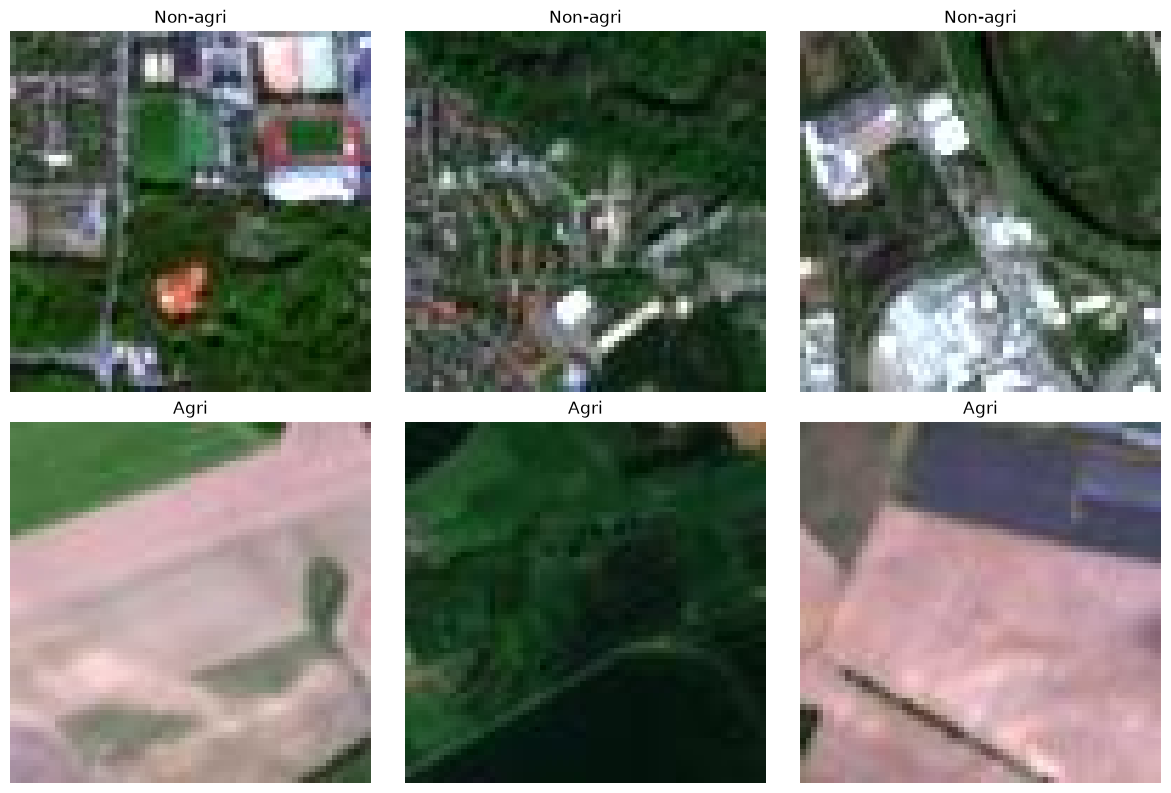

In [11]:
data_dir = Path("./data")
train_dir = data_dir / "train"
test_dir = data_dir / "test"

if train_dir.is_dir() and test_dir.is_dir():
    print("Train and test directories exist. The data is already setup for you.")

    # Display number of images in each subfolder
    for split_dir in [train_dir, test_dir]:
        print(f"\n{split_dir.name}:")
        
        for class_dir in split_dir.iterdir():
            if class_dir.is_dir():
                count = sum(1 for p in class_dir.iterdir() if p.is_file())
                print(f"  {class_dir.name}: {count}")
                
    # Display example data
    non_agri_dir = train_dir / "class_0_non_agri"
    non_agri_images = list(non_agri_dir.iterdir())
    agri_dir = train_dir / "class_1_agri"
    agri_images = list(agri_dir.iterdir())
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))

    for i, image_path in enumerate(non_agri_images[:3]):
        axes[0, i].imshow(Image.open(image_path))
        axes[0, i].set_title("Non-agri")
        axes[0, i].axis("off")
    
    for i, image_path in enumerate(agri_images[:3]):
        axes[1, i].imshow(Image.open(image_path))
        axes[1, i].set_title("Agri")
        axes[1, i].axis("off")
    
    plt.tight_layout()
    plt.show()
else:
    print("Please go on and execute the remaining notebook cells to set up the data.")

In [4]:
# Extract filename from URL
filename = Path(urlparse(data_url).path).name
tar_path = data_dir / filename

# Download only if the file doesn't already exist
if tar_path.exists():
    print(f"File already exists: {tar_path}")
else:
    response = requests.get(data_url, stream=True)
    response.raise_for_status()

    with open(filepath, "wb") as f:
        for chunk in response.iter_content(chunk_size=8192):
            if chunk:
                f.write(chunk)

    print(f"Downloaded to: {tar_path}")

File already exists: data/images-dataSAT.tar


### 2. Extract the data

In [5]:
extracted_dir = data_dir / "images_dataSAT"

if extracted_dir.exists():
    print(f"Data already extracted: {extracted_dir}")
else:
    with tarfile.open(tar_path, "r:*") as tar:
        tar.extractall(path=data_dir)
    print(f"Extracted data to: {data_dir}")

dir_non_agri = extracted_dir / "class_0_non_agri"
dir_agri = extracted_dir / "class_1_agri"

Extracted data to: data


In [6]:
# Get image paths
non_agri_images = list(dir_non_agri.iterdir())
agri_images = list(dir_agri.iterdir())

print(f"Non-agri images: {len(non_agri_images)}")
print(f"Agri images:     {len(agri_images)}")

Non-agri images: 3000
Agri images:     3000


### 3. Inspect the size of the data

In [7]:
# Print the size (width, height) of the first image in each class
with Image.open(non_agri_images[0]) as img:
    print(f"Non-agri first image size: {img.size}")
    print(f"Mode: {img.mode}")
    print(f"Channels: {len(img.getbands())}")
    
with Image.open(agri_images[0]) as img:
    print(f"Agri first image size:     {img.size}")
    print(f"Mode: {img.mode}")
    print(f"Channels: {len(img.getbands())}")

Non-agri first image size: (64, 64)
Mode: RGB
Channels: 3
Agri first image size:     (64, 64)
Mode: RGB
Channels: 3


### 4. Visualize a few images

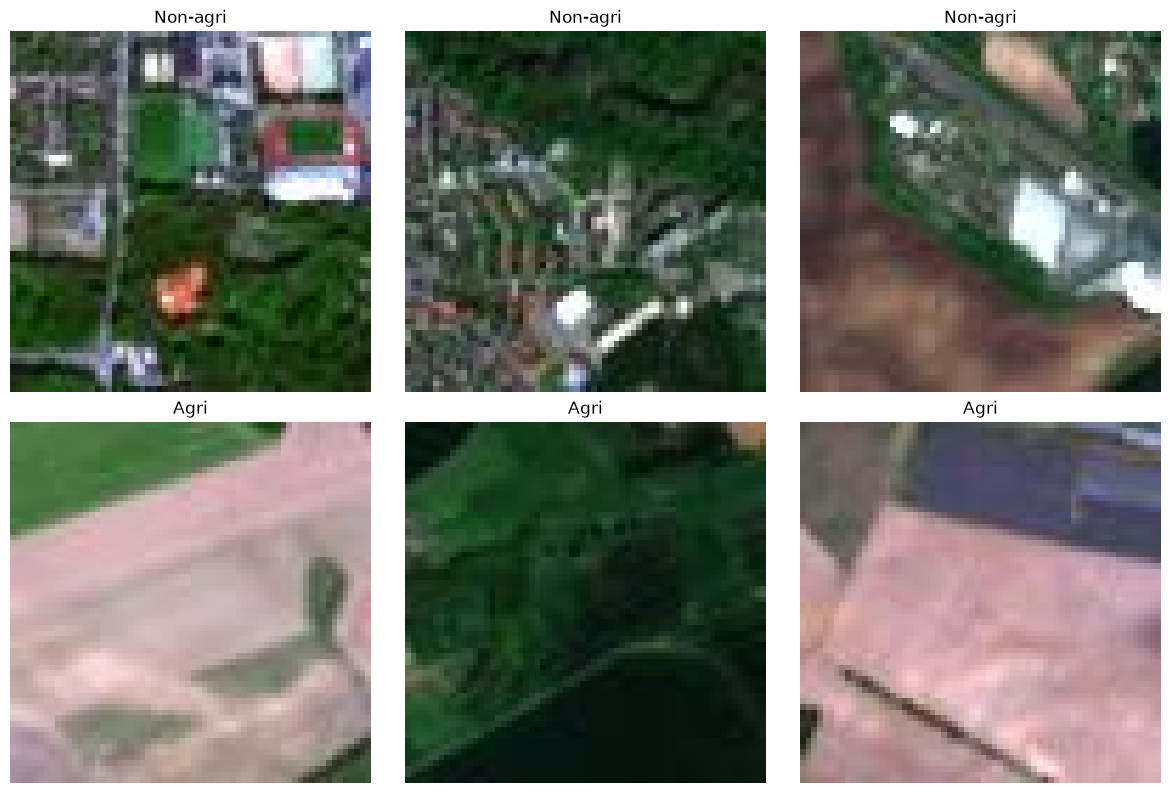

In [8]:
# Show the first 3 images from each class
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, image_path in enumerate(non_agri_images[:3]):
    axes[0, i].imshow(Image.open(image_path))
    axes[0, i].set_title("Non-agri")
    axes[0, i].axis("off")

for i, image_path in enumerate(agri_images[:3]):
    axes[1, i].imshow(Image.open(image_path))
    axes[1, i].set_title("Agri")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### 5. Keeping some test data unseen by the model

In [9]:
# How many images per class will be moved to the test folder - note that the total test dataset size is 2xtest_size_per_class, since we have 2 classes
test_size_per_class = 200 


if test_dir.exists():
    print(f"Test folder already exists: {test_dir}. Nothing to do.")

else:
    # Create class subfolders
    test_non_agri_dir = test_dir / "class_0_non_agri"
    test_agri_dir = test_dir / "class_1_agri"

    test_non_agri_dir.mkdir(parents=True)
    test_agri_dir.mkdir()

    # Randomly select 100 images from each class
    random.seed(42)

    test_non_agri = random.sample(non_agri_images, test_size_per_class)
    test_agri = random.sample(agri_images, test_size_per_class)

    # Move images to test subfolders
    for image_path in test_non_agri:
        shutil.move(str(image_path), str(test_non_agri_dir / image_path.name))

    for image_path in test_agri:
        shutil.move(str(image_path), str(test_agri_dir / image_path.name))

    print(f"Moved {test_size_per_class} images from each class into the test folder.")

    # Create train folder
    train_dir.mkdir()
    
    # Move the remaining original class folders into train
    shutil.move(str(dir_non_agri), str(train_dir / dir_non_agri.name))
    shutil.move(str(dir_agri), str(train_dir / dir_agri.name))
    
    print("Train and test folders created successfully.")

    extracted_dir.rmdir()

Moved 200 images from each class into the test folder.
Train and test folders created successfully.


In [10]:
for split_dir in [train_dir, test_dir]:
    print(f"\n{split_dir.name}:")
    
    for class_dir in split_dir.iterdir():
        if class_dir.is_dir():
            count = sum(1 for p in class_dir.iterdir() if p.is_file())
            print(f"  {class_dir.name}: {count}")


train:
  class_1_agri: 2800
  class_0_non_agri: 2800

test:
  class_1_agri: 200
  class_0_non_agri: 200
